# **libraries**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from imblearn.under_sampling import RandomUnderSampler

import warnings
warnings.filterwarnings("ignore")

from datasets import load_dataset

# **1– Load Dataset and Convert to CSV**

In [1]:
!pip install -U datasets fsspec

In [4]:
from datasets import load_dataset
import pandas as pd
ds = load_dataset("zeydferhat/arabic_functional_text_dimensions")
df = pd.DataFrame(ds['train'])
df.to_csv("arabic_functional_text_dimensions.csv", index=False)

print(df.info)
df.head()

<bound method DataFrame.info of       index                                               Text       label
0      2835  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...   Personal 
1      2867  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...    flippant
2       994  لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...       Legal
3       464  كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...    Instruct
4      2764  ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...   Personal 
...     ...                                                ...         ...
2375   1095  يمر النظام العالمي بمجموعة من التغيرات والتحول...  commercial
2376   1130  دعا محافظو البنوك الأفريقية، أمس الثلاثاء من ا...  commercial
2377   1294  عنابة هي ولاية ساحلية من شرق الجزائر. تقع على ...        info
2378    860  سياسة الاستعمال المقبول ((Acceptable use polic...       Legal
2379   3174  ارتفع عدد الوفود الممثلة لصناعة الوقود الأحفور...      report

[2380 rows x 3 columns]>


,index,Text,label
0,2835,وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...,Personal
1,2867,راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...,flippant
2,994,لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...,Legal
3,464,كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...,Instruct
4,2764,ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...,Personal


In [5]:
df['document_length'] = df['Text'].apply(len)
print(df[['Text', 'document_length']])

                                                   Text  document_length
0     وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...              772
1     راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...               59
2     لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...              176
3     كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...             1872
4     ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...              374
...                                                 ...              ...
2375  يمر النظام العالمي بمجموعة من التغيرات والتحول...            10761
2376  دعا محافظو البنوك الأفريقية، أمس الثلاثاء من ا...             1752
2377  عنابة هي ولاية ساحلية من شرق الجزائر. تقع على ...             1658
2378  سياسة الاستعمال المقبول ((Acceptable use polic...             6588
2379  ارتفع عدد الوفود الممثلة لصناعة الوقود الأحفور...             1098

[2380 rows x 2 columns]


In [7]:
import numpy as np
def average_word_length(text):
    words = text.split()
    if words:
        return np.mean([len(word) for word in words])
    return 0  # Handle empty documents

df['average_word_length'] = df['Text'].apply(average_word_length)
print(df[['Text', 'average_word_length']])

                                                   Text  average_word_length
0     وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...             3.923567
1     راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...             4.454545
2     لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...             3.783784
3     كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...             4.685976
4     ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...             5.250000
...                                                 ...                  ...
2375  يمر النظام العالمي بمجموعة من التغيرات والتحول...             5.273524
2376  دعا محافظو البنوك الأفريقية، أمس الثلاثاء من ا...             5.446494
2377  عنابة هي ولاية ساحلية من شرق الجزائر. تقع على ...             5.028000
2378  سياسة الاستعمال المقبول ((Acceptable use polic...             5.389105
2379  ارتفع عدد الوفود الممثلة لصناعة الوقود الأحفور...             4.956044

[2380 rows x 2 columns]


In [9]:
def punctuation_count(text):
    return sum([1 for char in text if char in string.punctuation])

df['punctuation_count'] = df['Text'].apply(punctuation_count)

def punctuation_ratio(text):
    text_length = len(text)
    if text_length > 0:
        return punctuation_count(text) / text_length
    return 0

df['punctuation_ratio'] = df['Text'].apply(punctuation_ratio)

print(df[['Text', 'punctuation_count', 'punctuation_ratio']].head())

                                                Text  punctuation_count  \
0  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...                 16   
1  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...                  1   
2  لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...                  1   
3  كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...                 42   
4  ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...                  5   

   punctuation_ratio  
0           0.020725  
1           0.016949  
2           0.005682  
3           0.022436  
4           0.013369  


In [10]:
import pandas as pd

def digit_count(text):
    return sum([1 for char in text if char.isdigit()])

df['digit_count'] = df['Text'].apply(digit_count)

def digit_ratio(text):
    text_length = len(text)
    if text_length > 0:
        return digit_count(text) / text_length
    return 0

df['digit_ratio'] = df['Text'].apply(digit_ratio)

print(df[['Text', 'digit_count', 'digit_ratio']].head())

                                                Text  digit_count  digit_ratio
0  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...            0     0.000000
1  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...            0     0.000000
2  لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...            0     0.000000
3  كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...           17     0.009081
4  ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...            0     0.000000


In [13]:
print(df.isnull().sum())



index                  0
Text                   0
label                  0
document_length        0
average_word_length    0
punctuation_count      0
punctuation_ratio      0
digit_count            0
digit_ratio            0
dtype: int64


In [14]:
#df.drop('index')
columns_to_keep = ['Text', 'label']
columns_to_drop = [col for col in df.columns if col not in columns_to_keep]

df_cleaned = df.drop(columns=columns_to_drop)

print(df_cleaned.head())
print(df_cleaned.info())

                                                Text      label
0  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...  Personal 
1  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...   flippant
2  لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...      Legal
3  كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...   Instruct
4  ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...  Personal 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    2380 non-null   object
 1   label   2380 non-null   object
dtypes: object(2)
memory usage: 37.3+ KB
None


# **2– Basic Exploration (shape, types, nulls)**

In [15]:

print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")

print("\nData Types:")
print(df.dtypes)


print("\nMissing Values:")
print(df.isnull().sum())

Number of rows: 2380, Number of columns: 9

Data Types:
index                    int64
Text                    object
label                   object
document_length          int64
average_word_length    float64
punctuation_count        int64
punctuation_ratio      float64
digit_count              int64
digit_ratio            float64
dtype: object

Missing Values:
index                  0
Text                   0
label                  0
document_length        0
average_word_length    0
punctuation_count      0
punctuation_ratio      0
digit_count            0
digit_ratio            0
dtype: int64


# **3– Descriptive Statistics for Text Length**

In [16]:

df["text_length_words"] = df["Text"].apply(lambda x: len(str(x).split()))
df["text_length_chars"] = df["Text"].apply(lambda x: len(str(x)))


df[["text_length_words", "text_length_chars"]].describe()

,text_length_words,text_length_chars
count,2380.000000,2380.000000
mean,212.695378,1286.353361
std,375.455674,2293.249322
min,2.000000,10.000000
25%,30.000000,174.000000
50%,94.000000,567.500000
75%,195.250000,1209.750000
max,5971.000000,37511.000000


# **4– Plot Distribution of Text Length (Words)**

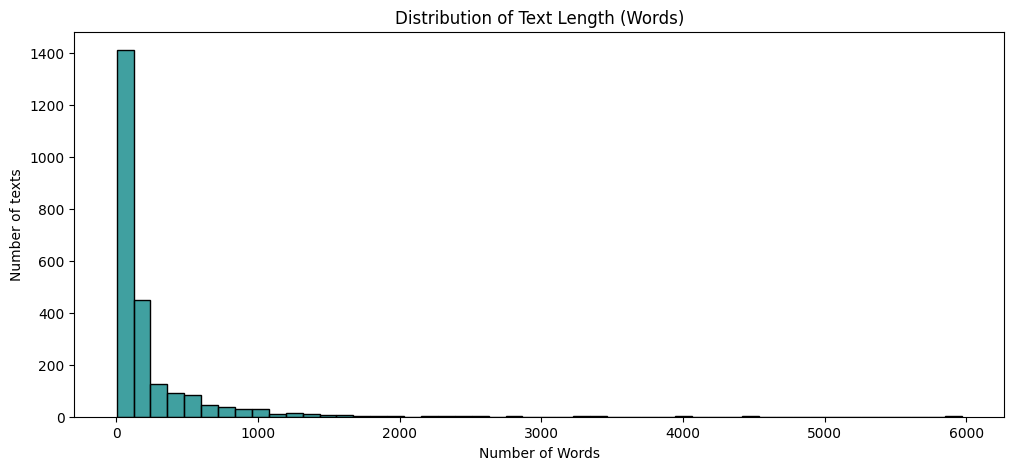

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.histplot(df["text_length_words"], bins=50, color='teal')
plt.title("Distribution of Text Length (Words)")
plt.xlabel("Number of Words")
plt.ylabel("Number of texts")
plt.show()

# **5– Plot Label Distribution**

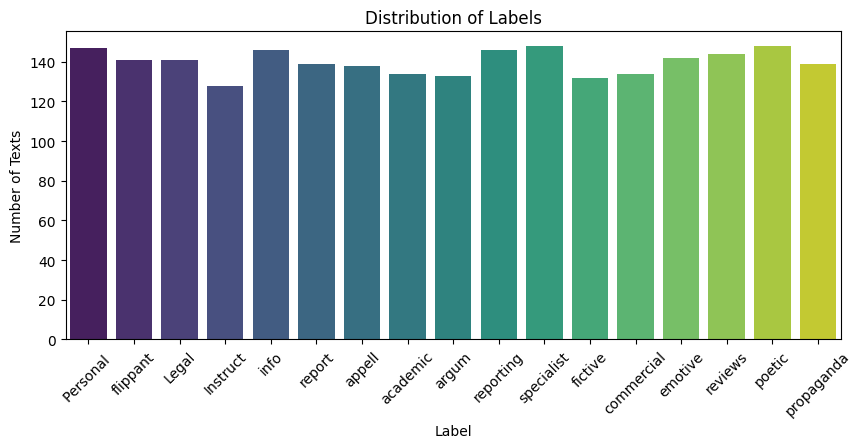

In [18]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="label", palette="viridis")
plt.title("Distribution of Labels")
plt.xlabel("Label")
plt.ylabel("Number of Texts")
plt.xticks(rotation=45)
plt.show()

# **6– Word Cloud (without custom Arabic Stopwords)**

In [19]:
from collections import Counter
import pandas as pd
import re

# Custom Arabic stopwords
arabic_stopwords = set([
    "في", "من", "على", "إلى", "عن", "ما", "أن", "إن", "كان", "كما", "قد", "لا",
    "لم", "لن", "هو", "هي", "هذا", "هذه", "ذلك", "أو", "أي", "كل", "لذلك", "فإن",
    "به", "بعد", "أكثر", "بين", "أقل", "حتى", "أمام", "تحت", "فوق", "مع", "لكن"
])

# Preprocessing function to clean text
def preprocess(text):
    text = re.sub(r'[^\w\s]', '', text)  # remove punctuation
    text = re.sub(r'[\u064B-\u0652]', '', text)  # remove diacritics
    return text

# Combine all text entries
all_text = " ".join(df["Text"].astype(str).apply(preprocess).values)

# Split into words
words = all_text.split()

# Remove stopwords and short words
filtered_words = [w for w in words if w not in arabic_stopwords and len(w) > 1]

# Count word frequencies
word_counts = Counter(filtered_words)

# Top 20 words
top_words = word_counts.most_common(20)

# Convert to DataFrame
top_words_df = pd.DataFrame(top_words, columns=["Word", "Number of repetitions"])
display(top_words_df)

,Word,Number of repetitions
0,التي,3349
1,الذي,1688
2,خلال,1044
3,إذا,856
4,العمل,824
5,حيث,812
6,يمكن,784
7,غير,747
8,بشكل,718
9,كانت,691


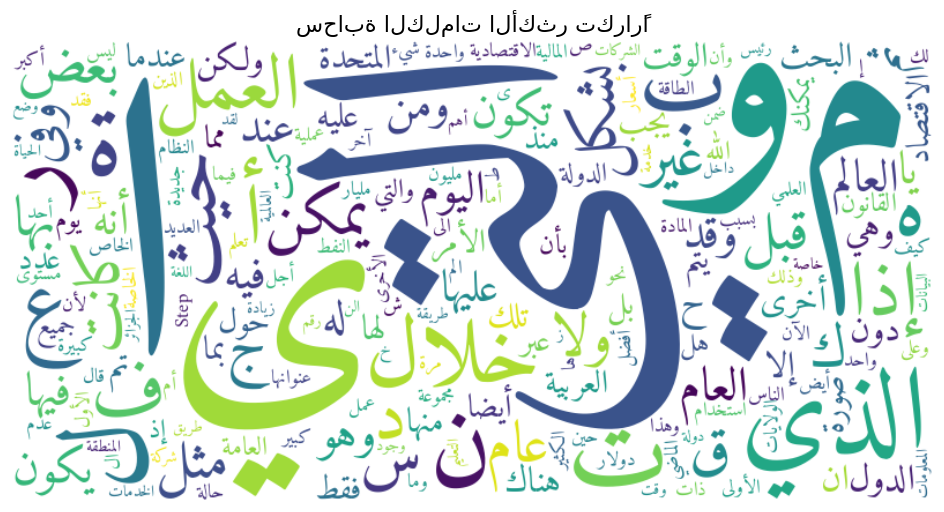

In [44]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from PIL import ImageFont


ImageFont.truetype('Amiri-Regular.ttf', size=24)


all_text = " ".join(df["Text"].astype(str).values)


arabic_stopwords = set([
    "في", "من", "على", "إلى", "عن", "ما", "أن", "إن", "كان", "كما", "قد", "لا",
    "لم", "لن", "هو", "هي", "هذا", "هذه", "ذلك", "أو", "أي", "كل", "لذلك", "فإن",
    "به", "بعد", "أكثر", "بين", "أقل", "حتى", "أمام", "تحت", "فوق", "مع", "لكن"
])


wordcloud = WordCloud(
    font_path='Amiri-Regular.ttf',
    width=800,
    height=400,
    background_color='white',
    stopwords=arabic_stopwords,
    collocations=False
).generate(all_text)


plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("سحابة الكلمات الأكثر تكرارًا", fontsize=16)
plt.show()

# **7- Preprocessing Code for Arabic Text Dataset**

In [45]:
import pandas as pd
import re
from nltk.stem.isri import ISRIStemmer


arabic_stopwords = set([
    "في", "من", "على", "إلى", "عن", "ما", "أن", "إن", "كان", "كما", "قد", "لا",
    "لم", "لن", "هو", "هي", "هذا", "هذه", "ذلك", "أو", "أي", "كل", "لذلك", "فإن",
    "به", "بعد", "أكثر", "بين", "أقل", "حتى", "أمام", "تحت", "فوق", "مع", "لكن"
])


stemmer = ISRIStemmer()

def preprocess_arabic(text):
    if pd.isnull(text): return ""


    text = re.sub(r'[\u064B-\u0652]', '', text)


    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)


    text = re.sub(r'\s+', ' ', text).strip()


    tokens = text.split()


    tokens = [word for word in tokens if word not in arabic_stopwords and len(word) > 1]


    stemmed_tokens = [stemmer.stem(word) for word in tokens]

    return ' '.join(stemmed_tokens)


In [46]:
df["cleaned_text"] = df["Text"].astype(str).apply(preprocess_arabic)
df[["Text", "cleaned_text"]].head()

,Text,cleaned_text
0,وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...,وحن نمت مرض جدد خطت عئد غرف زوج ولكن سمع صوت خ...
1,راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...,راح رجل دكتور سأل انت عند يه؟ قله عند عيل خرف
2,لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...,يجز عقب شخص جرم سبب عمل منع عمل يكن حين شكل جر...
3,كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...,كيف زلة بقع قلم حبر دئم حذي شرك ألف فرق عمل وي...
4,ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...,لخص حدث جزء اضي سفر ثنء رحل دين صغر اسم باد شا...


# **8- Handling Missing Values**

In [47]:
df.dropna(subset=["Text", "label"], inplace=True)

# **9- Outlier Detection (if applicable to numeric fields like text length)**

In [48]:
# Example: Detect outliers in word counts using IQR
df["text_length_words"] = df["cleaned_text"].apply(lambda x: len(x.split()))

Q1 = df["text_length_words"].quantile(0.25)
Q3 = df["text_length_words"].quantile(0.75)
IQR = Q3 - Q1

# Filter out outliers
df = df[(df["text_length_words"] >= Q1 - 1.5 * IQR) & (df["text_length_words"] <= Q3 + 1.5 * IQR)]


# **10- Feature Engineering**

In [49]:
import pandas as pd
import re
import numpy as np
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import StandardScaler


dataset = load_dataset("zeydferhat/arabic_functional_text_dimensions")
df = pd.DataFrame(dataset["train"])


print(" Dataset Info:")
df.info()
print("\n First 2 rows:")
print(df.head(2))


def basic_clean(text):
    if pd.isnull(text): return ""
    text = re.sub(r'[\u064B-\u0652]', '', text)
    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["clean_text"] = df["Text"].astype(str).apply(basic_clean)


df["doc_length"] = df["Text"].apply(lambda x: len(str(x)))
df["avg_word_length"] = df["Text"].apply(lambda x: np.mean([len(w) for w in str(x).split()]) if x else 0)
df["num_punctuations"] = df["Text"].apply(lambda x: len(re.findall(r'[^\w\s]', str(x))))
df["num_capitalized"] = df["Text"].apply(lambda x: len(re.findall(r'[A-Z]', str(x))))  # Useful for English text
df["num_digits"] = df["Text"].apply(lambda x: len(re.findall(r'\d', str(x))))

bow_vectorizer = CountVectorizer(max_features=1000)
bow_features = bow_vectorizer.fit_transform(df["clean_text"]).toarray()

tfidf_vectorizer = TfidfVectorizer(max_features=1000)
tfidf_features = tfidf_vectorizer.fit_transform(df["clean_text"]).toarray()


numeric_features = df[["doc_length", "avg_word_length", "num_punctuations", "num_capitalized", "num_digits"]]


scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(numeric_features)


final_features = np.concatenate([bow_features, scaled_numeric], axis=1)

print(f"\n Final feature matrix shape: {final_features.shape}")


 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   2380 non-null   int64 
 1   Text    2380 non-null   object
 2   label   2380 non-null   object
dtypes: int64(1), object(2)
memory usage: 55.9+ KB

 First 2 rows:
   index                                               Text      label
0   2835  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...  Personal 
1   2867  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...   flippant

 Final feature matrix shape: (2380, 1005)


# **11- Filter only legal documents**

In [51]:

columns_to_keep = ['Text', 'label']
columns_to_drop = [col for col in df.columns if col not in columns_to_keep]

df_cleaned = df.drop(columns=columns_to_drop)

print(df_cleaned.head())
print(df_cleaned.info())

                                                Text      label
0  وحين أنامته الممرضة من جديد خطوت عائدًا إلى غر...  Personal 
1  راح راجل للدكتور فسأله أنت عندك إيه؟ قاله عندي...   flippant
2  لا يجوز معاقبة أي شخص بجريمة بسبب أي عمل أو ام...      Legal
3  كيفية إزالة بقع قلم الحبر الدائم من الأحذية\nش...   Instruct
4  ملخّص أحداث الجزء الماضي: سافرتُ أثناء ترحالي ...  Personal 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    2380 non-null   object
 1   label   2380 non-null   object
dtypes: object(2)
memory usage: 37.3+ KB
None


In [ ]:
##legal_df = df[df['label'] == 'legal'].copy()
#legal_df = legal_df[['Text', 'label']]

#legal_df.info

# Add more categories manually if dataset is multiclass (mock example for demo)
For demonstration, let's sample from different labels for a multiclass classification task

In [52]:
unique_labels = df['label'].unique()
print(unique_labels)

['Personal ' 'flippant' 'Legal' 'Instruct' 'info' 'report' 'appell'
 'academic' 'argum' 'reporting' 'specialist' 'fictive' 'commercial'
 'emotive' 'reviews' 'poetic' 'propaganda']


In [55]:

sample_df = pd.concat([
    df_cleaned[df_cleaned['label'] == 'Legal'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'Personal '].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'report'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'Instruct'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'flippant'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'reviews'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'propaganda'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'emotive'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'appell'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'reporting'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'specialist'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'poetic'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'academic'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'info'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'argum'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'commercial'].sample(120, random_state=42),
    df_cleaned[df_cleaned['label'] == 'fictive'].sample(120, random_state=42)

])

In [56]:
print(sample_df['label'].value_counts())

arabic_stopwords = set(pd.read_csv("https://raw.githubusercontent.com/mohataher/arabic-stop-words/master/list.txt", header=None)[0].values)

label
Legal         120
Personal      120
report        120
Instruct      120
flippant      120
reviews       120
propaganda    120
emotive       120
appell        120
reporting     120
specialist    120
poetic        120
academic      120
info          120
argum         120
commercial    120
fictive       120
Name: count, dtype: int64


# **pre processing**

In [57]:
def preprocess_text(text):
    stemmer = ISRIStemmer()
    text = str(text)
    text = re.sub(r'[\d]+', '', text)  # remove digits
    text = re.sub(r'[{}]'.format(string.punctuation), '', text)  # remove punctuation
    text = re.sub(r'[\u064B-\u0652]', '', text)  # remove Arabic diacritics
    text = re.sub(r'\s+', ' ', text).strip()  # normalize whitespace
    tokens = text.split()
    tokens = [word for word in tokens if word not in arabic_stopwords]
    #stemmed_tokens = [stemmer.stem(word) for word in tokens] بتقلل ال accuracy
    return ' '.join(tokens)

# Apply preprocessing
sample_df['clean_text'] = sample_df['Text'].apply(preprocess_text)

# **features**

In [59]:
sample_df['document_length'] = sample_df['clean_text'].apply(len)
print(sample_df[['Text', 'document_length']])

                                                   Text  document_length
1191  المادة (١ (\nيسمى هذا النظام "القانون " (نظام ...             1584
1844  المرسوم الرئاسي رقم 05-159\nالمرسوم الرئاسي رق...              300
534   يعد إبرام عقد اتفاق مع شخص ما للحصول على خدمات...              308
874   تزايد القلق بشأن البيئة وحمايتها في السنوات ال...              308
1675  إن إصدار القاضي للحكم في أي قضية مرفوعة لديه. ...              213
...                                                 ...              ...
1829  لا يحْمِلُ الحِقْدَ مَنْ تَعْلُو بِهِ الرُّتَب...             1019
1780  أبكيك لو نقع الغليل بكائي، وَأقُولُ لَوْ ذَهَب...              343
2015  يُحكى أن مزارعاً مخادعاً قام ببيع بئر الماء ال...              478
1566  هام الفـؤاد بروضـك الريان أسمى اللغات ربيبة ال...              187
2112  ولّى الصّيامُ وجاءَ الفطرُ بالفرحِ وأبْدَتِ ال...              187

[2040 rows x 2 columns]


In [78]:
def average_word_length(text):
    words = text.split()
    if words:
        return np.mean([len(word) for word in words])
    return 0

sample_df['average_word_length'] = sample_df['clean_text'].apply(average_word_length)
print(sample_df[['clean_text', 'average_word_length']])

                                             clean_text  average_word_length
1191  المادة يسمى النظام القانون نظام قانون الجمارك ...             5.921397
1844  المرسوم الرئاسي رقم المرسوم الرئاسي رقم المؤرخ...             6.341463
534   يعد إبرام عقد اتفاق شخص للحصول خدمات سلع طريق ...             5.180000
874   تزايد القلق بشأن البيئة وحمايتها السنوات الأخي...             5.717391
1675  إصدار القاضي للحكم قضية مرفوعة سيكون الحكم الص...             5.114286
...                                                 ...                  ...
1829  يحمل الحقد تعلو الرتب ينال العلى طبعه الغضب يك...             4.862069
1780  أبكيك نقع الغليل بكائي، وأقول المقال بدائي وأع...             5.142857
2015  يحكى مزارعا مخادعا ببيع بئر الماء الموجود أرضه...             4.987500
1566  هام الفـؤاد بروضـك الريان أسمى اللغات ربيبة ال...             5.266667
2112  ولى الصيام وجاء الفطر بالفرح وأبدت الكأس ألوان...             4.875000

[2040 rows x 2 columns]


In [61]:
def punctuation_count(text):
    return sum([1 for char in text if char in string.punctuation])

sample_df['punctuation_count'] = sample_df['Text'].apply(punctuation_count)

def punctuation_ratio(text):
    text_length = len(text)
    if text_length > 0:
        return punctuation_count(text) / text_length
    return 0

sample_df['punctuation_ratio'] = sample_df['Text'].apply(punctuation_ratio)

print(sample_df[['Text', 'punctuation_count', 'punctuation_ratio']].head())

                                                   Text  punctuation_count  \
1191  المادة (١ (\nيسمى هذا النظام "القانون " (نظام ...                 83   
1844  المرسوم الرئاسي رقم 05-159\nالمرسوم الرئاسي رق...                  6   
534   يعد إبرام عقد اتفاق مع شخص ما للحصول على خدمات...                  4   
874   تزايد القلق بشأن البيئة وحمايتها في السنوات ال...                  1   
1675  إن إصدار القاضي للحكم في أي قضية مرفوعة لديه. ...                  4   

      punctuation_ratio  
1191           0.040174  
1844           0.013274  
534            0.010363  
874            0.002732  
1675           0.013652  


In [62]:
def digit_count(text):
    return sum([1 for char in text if char.isdigit()])

sample_df['digit_count'] = df['Text'].apply(digit_count)

def digit_ratio(text):
    text_length = len(text)
    if text_length > 0:
        return digit_count(text) / text_length
    return 0

sample_df['digit_ratio'] = sample_df['Text'].apply(digit_ratio)

print(sample_df[['Text', 'digit_count', 'digit_ratio']].head())

                                                   Text  digit_count  \
1191  المادة (١ (\nيسمى هذا النظام "القانون " (نظام ...           27   
1844  المرسوم الرئاسي رقم 05-159\nالمرسوم الرئاسي رق...           41   
534   يعد إبرام عقد اتفاق مع شخص ما للحصول على خدمات...            0   
874   تزايد القلق بشأن البيئة وحمايتها في السنوات ال...            5   
1675  إن إصدار القاضي للحكم في أي قضية مرفوعة لديه. ...            0   

      digit_ratio  
1191     0.013069  
1844     0.090708  
534      0.000000  
874      0.013661  
1675     0.000000  


In [63]:
from sklearn.preprocessing import StandardScaler

numeric_features = sample_df[["document_length", "average_word_length", "punctuation_count", "digit_ratio"]]
scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(numeric_features)


In [64]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=1000)
tfidf_features = tfidf.fit_transform(sample_df["clean_text"]).toarray()


In [65]:
import numpy as np

final_features = np.concatenate([tfidf_features, scaled_numeric], axis=1)

In [66]:
#from sklearn.preprocessing import LabelEncoder

#le = LabelEncoder()
#y = le.fit_transform(df["label"])  # or whatever your label column is


# **model**

In [67]:
# Split data
X = sample_df['clean_text']
y = sample_df['label']



X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=41, stratify=y)

In [68]:
print("\nHyperparameter Tuning (Random Forest):")
pipeline_rf = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'\b\w+\b', ngram_range=(1, 2), max_df=1.0, min_df=1)),
    ('clf', RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 20, 40],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 3],
    'clf__max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1, verbose=2)
grid_rf.fit(X_train, y_train)

print("\nBest RF params:", grid_rf.best_params_)
print("Best RF score:", grid_rf.best_score_)
y_pred_rf_grid = grid_rf.predict(X_test)





Hyperparameter Tuning (Random Forest):
Fitting 5 folds for each of 48 candidates, totalling 240 fits

Best RF params: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best RF score: 0.6255980187988969


In [75]:
# Define models
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    'random forest': RandomForestClassifier(n_estimators=1000, random_state=41),
    #'gradient boost':GradientBoostingClassifier(n_estimators=200)

}


Naive Bayes Classification Report:
              precision    recall  f1-score   support

    Instruct       0.50      0.96      0.66        24
       Legal       0.92      0.96      0.94        24
   Personal        0.75      0.62      0.68        24
    academic       0.80      0.67      0.73        24
      appell       0.95      0.83      0.89        24
       argum       0.31      0.67      0.42        24
  commercial       0.38      1.00      0.55        24
     emotive       0.73      0.33      0.46        24
     fictive       0.65      0.46      0.54        24
    flippant       0.79      0.62      0.70        24
        info       0.88      0.58      0.70        24
      poetic       0.73      0.79      0.76        24
  propaganda       0.77      0.42      0.54        24
      report       0.71      0.42      0.53        24
   reporting       0.67      0.25      0.36        24
     reviews       0.95      0.79      0.86        24
  specialist       0.87      0.54      0.67  

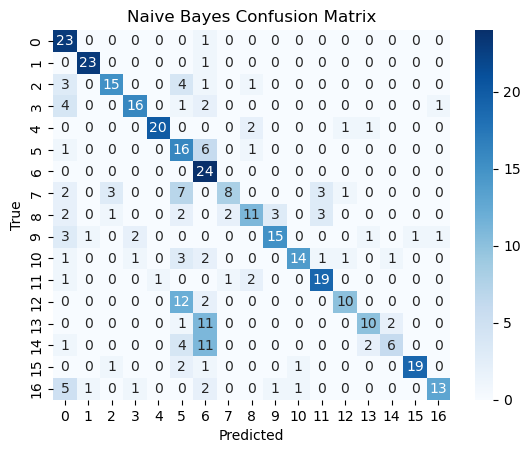


Logistic Regression Classification Report:
              precision    recall  f1-score   support

    Instruct       0.85      0.96      0.90        24
       Legal       0.77      0.96      0.85        24
   Personal        0.65      0.71      0.68        24
    academic       0.83      0.62      0.71        24
      appell       0.59      0.83      0.69        24
       argum       0.53      0.75      0.62        24
  commercial       0.64      0.96      0.77        24
     emotive       0.82      0.58      0.68        24
     fictive       0.63      0.50      0.56        24
    flippant       0.68      0.71      0.69        24
        info       0.70      0.67      0.68        24
      poetic       0.71      0.62      0.67        24
  propaganda       0.79      0.62      0.70        24
      report       0.79      0.62      0.70        24
   reporting       0.65      0.46      0.54        24
     reviews       0.90      0.79      0.84        24
  specialist       0.86      0.79    

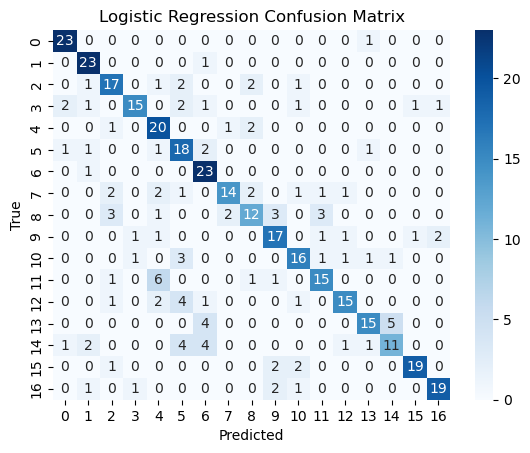


SVM Classification Report:
              precision    recall  f1-score   support

    Instruct       0.95      0.88      0.91        24
       Legal       0.95      0.83      0.89        24
   Personal        0.53      0.75      0.62        24
    academic       0.87      0.54      0.67        24
      appell       0.68      0.79      0.73        24
       argum       0.67      0.75      0.71        24
  commercial       0.81      0.88      0.84        24
     emotive       0.47      0.75      0.58        24
     fictive       0.61      0.46      0.52        24
    flippant       0.84      0.67      0.74        24
        info       0.39      0.75      0.51        24
      poetic       0.78      0.29      0.42        24
  propaganda       0.90      0.79      0.84        24
      report       0.88      0.58      0.70        24
   reporting       0.62      0.54      0.58        24
     reviews       0.95      0.79      0.86        24
  specialist       0.78      0.88      0.82        24

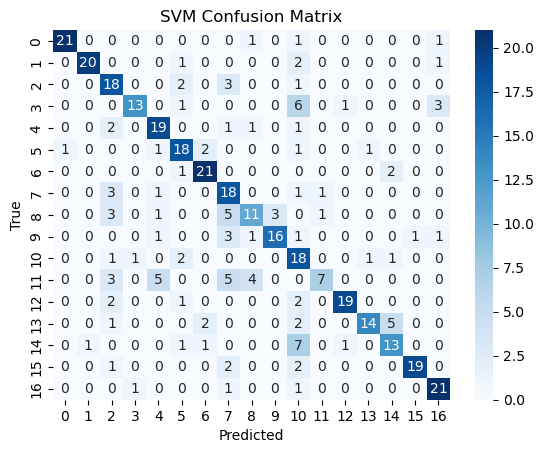


random forest Classification Report:
              precision    recall  f1-score   support

    Instruct       0.88      0.96      0.92        24
       Legal       0.72      0.88      0.79        24
   Personal        0.60      0.38      0.46        24
    academic       0.80      0.17      0.28        24
      appell       0.17      1.00      0.28        24
       argum       0.94      0.67      0.78        24
  commercial       0.69      0.75      0.72        24
     emotive       0.33      0.29      0.31        24
     fictive       1.00      0.33      0.50        24
    flippant       0.70      0.29      0.41        24
        info       0.90      0.38      0.53        24
      poetic       1.00      0.21      0.34        24
  propaganda       0.52      0.46      0.49        24
      report       0.71      0.62      0.67        24
   reporting       0.69      0.46      0.55        24
     reviews       0.80      0.67      0.73        24
  specialist       0.62      0.33      0.43

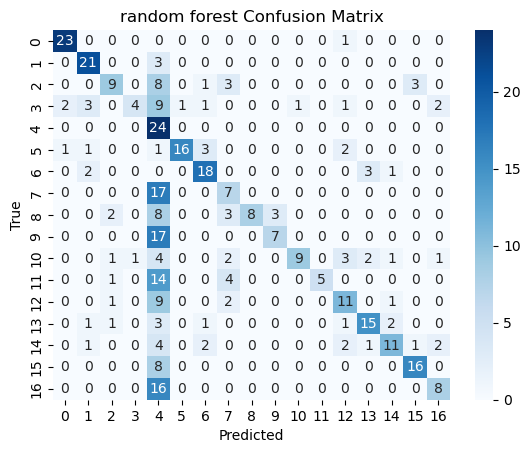

In [20]:
# Create TF-IDF + Classifier pipeline and evaluate
for name, model in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=r'\b\w+\b', ngram_range=(1, 2), max_df=1.0, min_df=1)),
        ('clf', model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    print(f"\n{name} Classification Report:")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()


# **hyper parameter tuining**

In [76]:
param_grid = {
    'clf__C': [0.01, 0.1, 1, 10],
    'clf__penalty': ['l2']
}

In [77]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'\b\w+\b', ngram_range=(1, 2), max_df=1.0, min_df=1)),
    ('clf', LogisticRegression(max_iter=1000))
])

grid = GridSearchCV(pipeline, param_grid, cv=3, scoring='accuracy')
grid.fit(X_train, y_train)


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(ngram_range=(1, 2),
                                                        token_pattern='\\b\\w+\\b')),
                                       ('clf',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l2']},
             scoring='accuracy')

In [79]:
print("\nBest parameters (Logistic Regression):", grid.best_params_)
y_pred = grid.predict(X_test)
print("\nTuned Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred))



Best parameters (Logistic Regression): {'clf__C': 10, 'clf__penalty': 'l2'}

Tuned Logistic Regression Classification Report:
              precision    recall  f1-score   support

    Instruct       0.92      0.96      0.94        24
       Legal       0.80      1.00      0.89        24
   Personal        0.65      0.71      0.68        24
    academic       0.80      0.67      0.73        24
      appell       0.67      0.83      0.74        24
       argum       0.56      0.75      0.64        24
  commercial       0.70      0.96      0.81        24
     emotive       0.78      0.58      0.67        24
     fictive       0.57      0.50      0.53        24
    flippant       0.73      0.67      0.70        24
        info       0.64      0.67      0.65        24
      poetic       0.70      0.67      0.68        24
  propaganda       0.81      0.71      0.76        24
      report       0.83      0.62      0.71        24
   reporting       0.64      0.58      0.61        24
     rev

# **GUI**

In [80]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("zeydferhat/arabic_functional_text_dimensions")
df = pd.DataFrame(dataset['train'])

print(df.columns)

Index(['index', 'Text', 'label'], dtype='object')


In [81]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# التأكد من اسم العمود: "sentence"
X_train, X_test, y_train, y_test = train_test_split(df['Text'], df['label'], test_size=0.2, random_state=42)

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [82]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

LogisticRegression()

In [83]:
def predict(text):
    text_tfidf = vectorizer.transform([text])
    prediction = model.predict(text_tfidf)
    return prediction[0]


In [86]:
import gradio as gr

interface = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(label="أدخل النص هنا"),
    outputs="text",
    title="تصنيف النصوص العربية",
    description="ادخل نصًا وسيتم تصنيفه إلى نوعه الوظيفي"
)

interface.launch()